# Real Hawaii gravity to an effective density volume


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `hawaii_gravity_density_volume` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：latitude (1, 1019) float64：WGS84 latitude, decimal degrees north.；longitude (1, 1019) float64：WGS84 longitude, decimal degrees east; west is negative.；elevation (1, 1019) float64：Orthometric elevation above sea level, m.；observed_gravity (1, 1019) float64：Original measured downward gravity, mGal; 1 mGal=10^-5 m/s^2.。恢复目标：三维密度差体，g/cm³。

获取模型：normal gravity/地形校正和趋势投影后，三维prism Newton重力核乘密度。实际恢复算法：solvers.reconstruct/newton_cg：空间差分正则二次逆；physics_model.gravity_matrix显式prism积分。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:45原始标准密度体；kernel是算子校准，不是真密度。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：hawaii_gravity_density_volume.ipynb单元5：5. Results；Computed regularization sensitivity；Convergence, depth sensitivity and nonuniqueness；hawaii_gravity_density_volume.ipynb单元7有保存图；axes[1,0].set(xlabel='Orthometric station height (m)',ylabel='Measured minus normal gravity (mGal)',title='Height dependence before correction')；axes[1,1].set(xlabel='Reduced obser；hawaii_gravity_density_volume.ipynb单元8有保存图；图内容由该单元调用的本地visualization函数生成；hawaii_gravity_density_volume.ipynb单元9有保存图；图内容由该单元调用的本地visualization函数生成；hawaii_gravity_density_volume.ipynb单元10有保存图；axes[0,0].set(xlabel='Evaluated Newton state',ylabel='Weighted objective',title='Actual one-step quadratic convergence');axes[0,0].legend(fontsize=8)；axes[0,1].set(xlabel='Evaluate。图/比较代码位于单元7, 8, 9, 10（从0计数）。代码单元5个，带execution_count的5个，保存PNG输出4幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Recover a signed effective three-dimensional density contrast from real surface gravity stations. Gravity integrates over source volume, so depth, lateral extent and regional background are strongly confounded.

This notebook actively reconstructs the full bound set of 1019 real USGS historical stations on a 16 by 16 by 8 rectangular-prism volume. Upstream means the actual independent unmodified SimPEG run on exactly these observations. Fresh means local calculations below. No true underground density is available, and neither reconstruction is called geological truth.

Gravity is a broad spatial integral. Its depth ambiguity, finite survey coverage, approximate topographic reductions and regional nuisance field make the recovered volume conditional on a chosen model. This experiment validates a published regularized inversion and explicit physical operators rather than claiming to discover a uniquely identified intrusion.


## 2. Data

The full bound set contains 1019 unchanged historical USGS stations with WGS84 coordinates, absolute downward gravity and orthometric heights. The fixed 16 by 16 by 8 prism volume is 48 km wide and 20 km deep. No underground density truth exists.

The visible arrays are selected unchanged from the original historical data table. No target density, truth model or fitted density-derived calibration is supplied.

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| latitude | (1,1019) | float64 | WGS84 latitude, decimal degrees north. |
| longitude | (1,1019) | float64 | WGS84 longitude, decimal degrees east; west is negative. |
| elevation | (1,1019) | float64 | Orthometric elevation above sea level, m. |
| observed_gravity | (1,1019) | float64 | Original measured downward gravity, mGal; 1 mGal=10^-5 m/s^2. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Latitude selection | 19.25 < latitude < 19.55 | deg north | Native irregular survey region. |
| Longitude selection | -155.45 < longitude < -155.10 | deg east | Native irregular survey region. |
| Cartesian origin latitude | 19.4 | deg north | a0 for the local projection. |
| Cartesian origin longitude | -155.275 | deg east | longitude0 for the local projection. |
| Projection Earth radius | 6371000 | m | RE in x/y conversion. |
| Vertical origin | orthometric sea level | m | Station z=elevation; source prism top at z=0. |
| Volume x bounds | -24000 to 24000 | m | 16 uniform east-west cells. |
| Volume y bounds | -24000 to 24000 | m | 16 uniform south-north cells. |
| Volume z bounds | -20000 to 0 | m | 8 uniform bottom-to-top cells. |
| Cell widths x,y,z | 3000,3000,2500 | m | Fixed physical discretization. |
| Gravitational constant | 6.67430e-11 | m^3 kg^-1 s^-2 | Newtonian gravity convention. |
| Slab reduction density | 2670 | kg/m^3 | rhoB, equivalent to 2.67 g/cm^3. |
| Linear free-air coefficient | 0.3086 | mGal/m | Height-reduction approximation. |
| Normal-gravity equatorial value | 978032.53359 | mGal | n(a) convention. |
| Normal-gravity numerator coefficient | 0.00193185265241 | 1 | Somigliana latitude dependence. |
| Normal-gravity eccentricity squared | 0.00669437999013 | 1 | Ellipsoidal latitude convention. |
| Regional nuisance basis | 1,x/10000,y/10000 | 1 | Unweighted orthogonal plane projection, same on data and model. |
| Exterior model | zero density contrast outside the finite box | g/cm^3 | Does not assert absence of external geological structures. |
| Survey lineage | historical stations through 1999, published dataset 2017 | year | Earlier GS stations and later LaCoste-Romberg measurements. |


## 3. Physics

For density vector $\rho$, prism gravity matrix $K$ and orthogonal regional-plane projector $P$, the modeled upward anomaly is $d=PK\rho+\epsilon$. Here $d$ is the explicitly reduced measured gravity in mGal and $\epsilon$ includes reduction/model discrepancy. Projection must act on both data and every operator column. Newtonian volume integration sets the density/sign/scale conventions.

Use 1019 real historical USGS stations in the Kilauea region of the island of Hawai'i. The task reconstructs an effective density contrast in a fixed sea-level-and-below rectangular prism volume. It is a conditional standard inverse under the stated reductions, not a claim that the recovered values are independently measured true geology or a reproduction of the historical survey's published geological model.

Let g be measured downward gravity in mGal, h orthometric station elevation in m, and latitude a in radians. Normal gravity is n(a)=978032.53359(1+0.00193185265241 sin(a)^2)/sqrt(1-0.00669437999013 sin(a)^2) mGal. Define the simple-Bouguer quantity b by


$$
b=g-n(a)+0.3086h-\left(2\pi G\rho_{\mathrm{B}}h\right)10^5.
$$


Here G is the gravitational constant and rhoB=2670 kg/m^3. The factor 10^5 converts only the SI Bouguer-slab acceleration term to mGal. The linear height correction and infinite-slab Bouguer correction are adopted approximations; detailed terrain and curvature corrections are unavailable and are not silently assumed.

Set x=RE cos(a0)(longitude-longitude0), y=RE(latitude-latitude0), using angular differences in radians and the reference coordinates below. T has three columns [1,x/10000,y/10000]. P=I-T(T^T T)^(-1)T^T removes a regional plane. Apply P to both measured residuals and forward predictions, so an arbitrary nuisance plane is consistently marginalized:


$$
d=-Pb,\qquad d=PK\rho+\epsilon,\qquad
K_{ij}=10^8G\int_{V_j}\frac{z-z_i}{[(x-x_i)^2+(y-y_i)^2+(z-z_i)^2]^{3/2}}\,dV.
$$


Here d is the upward residual gravity, rho is the vector of constant prism density contrasts in g/cm^3, V_j is prism j, (x_i,y_i,z_i) is station i, and epsilon represents observational and modeling discrepancies after projection. The factor 10^8 combines g/cm^3 to kg/m^3 and m/s^2 to mGal. Positive density below a receiver produces negative upward gravity. The Earth-radius projection is a local Cartesian approximation, not a geodetic reprojection requiring another library.


## 4. Method

The local eight-corner prism formula and fixed-beta cell-volume smallness/gradient regularizer define a quadratic objective. The selected Newton-CG method accepts a single full Newton step; the zero initialization and accepted endpoint are actual states rather than an invented long convergence curve.

The prism acquisition operator is linear in density, but broad depth sensitivity makes its inverse ill-conditioned. A weighted least-squares fit with cell-volume-weighted smallness and three spatial-gradient penalties selects a smooth finite-volume solution. Natural zero exterior normal derivatives provide a regularization boundary convention. Compute the prism kernel explicitly and include the same regional projection in its likelihood and gradient. A Newton step with a general conjugate-gradient linear solve is suitable for this quadratic objective; use physically scaled regularization rather than interpreting a shallow concentrated fit as uniquely determined geology.


## 5. Results

The retained station maps, depth slices, original/local differences, three fresh beta inversions, endpoint objectives and singular-value/column-norm diagnostics separate numerical reproduction from identifiability. The 5 mGal discrepancy scale is an adopted modeling tolerance, not measured gravimeter noise.

### Measured stations and explicit gravity reduction

The public input is absolute downward gravity, WGS84 coordinates and orthometric heights. We remove the specified latitude normal-gravity value, apply a linear free-air and an infinite-slab Bouguer correction, then remove a fitted plane. These approximations do not include a detailed terrain model. The same orthogonal plane projection acts on every column of the prism operator, and the final likelihood is upward projected gravity in mGal.

The inversion weights use a 5 mGal model-discrepancy convention. This is not an independently measured gravimeter noise level. Source metadata does not give formal uncertainty tests. Maps below show native stations with no interpolation or manufactured image samples.

### Three-dimensional spatial reconstruction

The mesh spans 48 km by 48 km laterally and 20 km downward from sea level. Density contrast is signed in g/cm^3. The output order is bottom-to-top z, south-to-north y and west-to-east x. Three depth planes compare the independent standard inverse, fresh local inverse and their direct difference. All cells are scored without alignment. Original/fresh panels use identical symmetric density limits.

Matching a standard inverse validates reproducibility; it does not establish true density. Regional projection removes information, finite-volume support is assumed, and many different density distributions can fit the same surface field.

### Computed regularization sensitivity

The objective is the squared norm of the gravity residual divided by 5 mGal, plus beta times a cell-volume smallness and three physical-gradient penalties. The standard beta is 0.001. The following three beta settings are actively reconstructed from raw observations in this cell. They are numerical sensitivity experiments, not historical or cached measurements.

The deeper part of the volume is weakly determined. Changing regularization can change the inferred amplitude and depth pattern even when a relatively small surface residual is obtained. Each row uses a common color scale across all three actual inverses.

### Convergence, depth sensitivity and nonuniqueness

The likelihood and regularizer are quadratic, so the selected Newton-CG method accepts a single full Newton step. Two plotted evaluated states are the actual zero initialization and accepted solution. An artificial long convergence curve would be misleading. The original objective endpoints come from its actual captured initial/final objective evaluations.

Column norms show the relative contribution of unit-density cells, while singular values describe the projected measured subspace. Neither is a spatial-resolution map. There are fewer measured samples than density cells, and removing a regional plane reduces independent data information further. The smooth solution and the small residual must therefore be interpreted together.


In [1]:
from pathlib import Path
import os,time,json,hashlib,importlib.util,sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,prepare_observations
from src.solvers import reconstruct
from src.visualization import station_map,density_slice
data=load_data();upstream=dict(np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False))
export=Path(os.environ.get('IMAGING_PRIVATE_FIGURES','output/review_figures'));export.mkdir(parents=True,exist_ok=True)
manifest=[]
def save_group(fig,name,**arrays):
    fig.tight_layout()
    for extension in ['png','svg','pdf']:
        path=export/(name+'.'+extension);fig.savefig(path,dpi=170,bbox_inches='tight')
        manifest.append(dict(file=path.name,bytes=path.stat().st_size,sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
    path=export/(name+'_source.npz');np.savez_compressed(path,**arrays)
    manifest.append(dict(file=path.name,bytes=path.stat().st_size,sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
    plt.show()
started=time.perf_counter();fresh,state=reconstruct(data);runtime=time.perf_counter()-started
residual=state['prediction']-state['anomaly'];reference=upstream['reconstruction']
ncc=float(np.vdot(fresh.ravel(),reference.ravel())/(np.linalg.norm(fresh)*np.linalg.norm(reference)))
nrmse=float(np.sqrt(np.mean((fresh-reference)**2))/np.ptp(reference))
measurements=dict(seconds=runtime,ncc=ncc,dynamic_range_nrmse=nrmse,maximum_density_difference=float(np.max(np.abs(fresh-reference))),observation_rms_mgal=float(np.sqrt(np.mean(residual**2))),newton_steps=len(state['steps']))
display(measurements)
np.savez_compressed('output/reconstruction.npz',reconstruction=fresh[None])
spec=importlib.util.spec_from_file_location('standalone_review_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,status=judge.evaluate('output/reconstruction.npz');assert status==0,report
display(report)
np.savez_compressed('notebooks/reference_outputs/fresh.npz',reconstruction=fresh,prediction=state['prediction'],history=state['history'],runtime_seconds=runtime)


{'seconds': 1.4626905000004626,
 'ncc': 0.9999999999999999,
 'dynamic_range_nrmse': 4.393173273782605e-13,
 'maximum_density_difference': 1.7522233664024611e-12,
 'observation_rms_mgal': 1.7411629807404885,
 'newton_steps': 1}

{'status': 'pass',
 'passed': True,
 'metrics': {'density_ncc': 0.9999999999999999,
  'density_nrmse': 4.393173273782605e-13,
  'observation_rms_mgal': 1.7411629807404865},
 'thresholds': {'density_ncc': {'comparison': '>=', 'boundary': 0.999999999},
  'density_nrmse': {'comparison': '<=', 'boundary': 1e-07},
  'observation_rms_mgal': {'comparison': '<=', 'boundary': 2.0}},
 'errors': []}

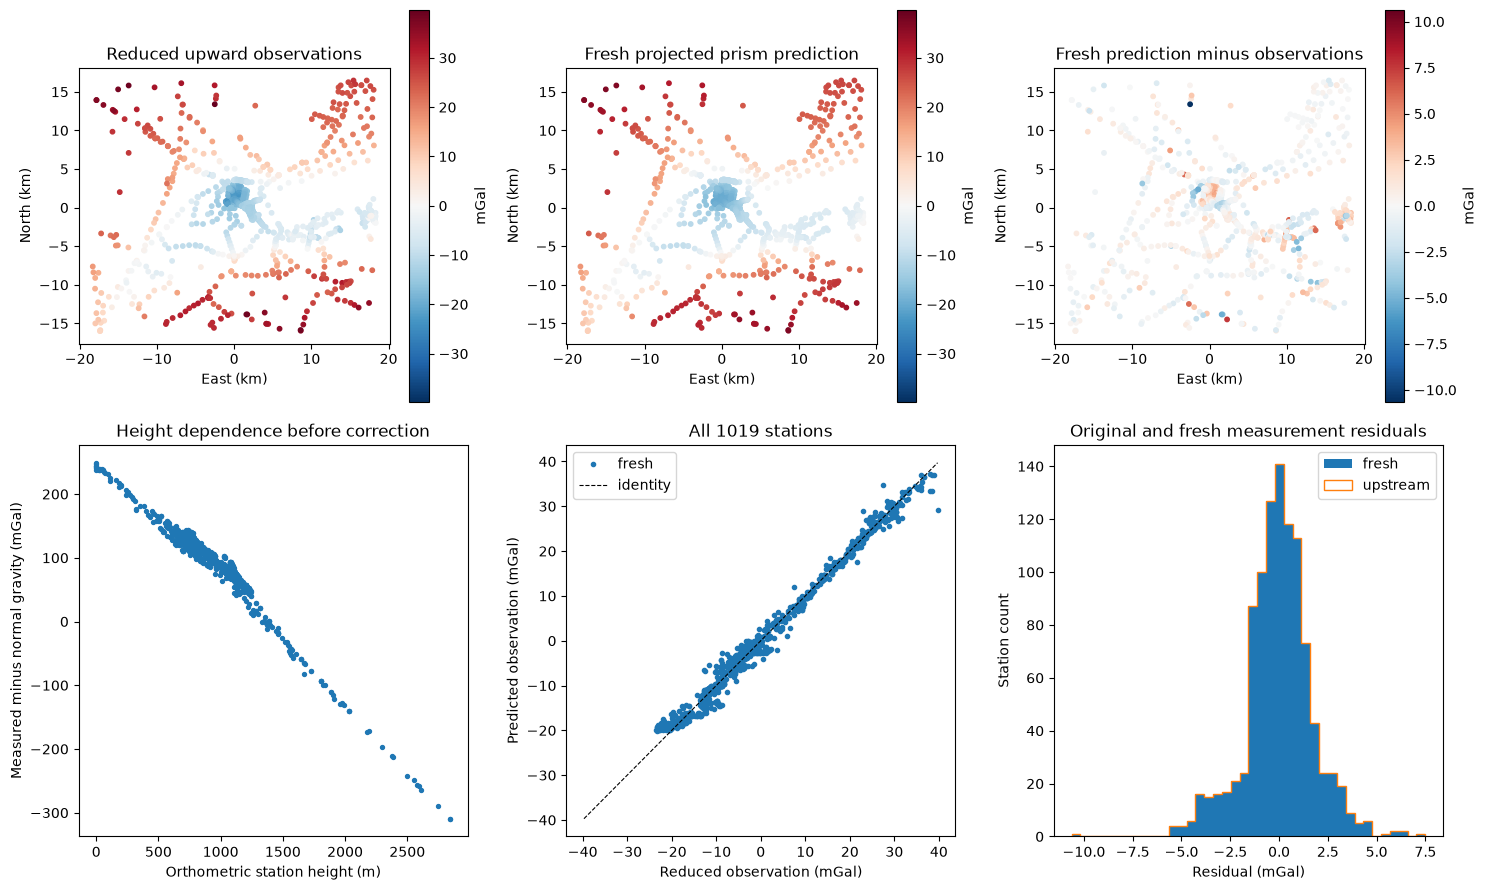

In [2]:
fig,axes=plt.subplots(2,3,figsize=(15,9))
locations=state['locations'];lim=max(np.max(np.abs(state['anomaly'])),np.max(np.abs(state['prediction'])))
for ax,values,title,limits in [(axes[0,0],state['anomaly'],'Reduced upward observations',(-lim,lim)),(axes[0,1],state['prediction'],'Fresh projected prism prediction',(-lim,lim)),(axes[0,2],residual,'Fresh prediction minus observations',(-max(abs(residual)),max(abs(residual))))]:
    image=station_map(ax,locations,values,title,limits);fig.colorbar(image,ax=ax,label='mGal')
axes[1,0].scatter(data['elevation'],data['observed_gravity']-state['normal_gravity'],s=8)
axes[1,0].set(xlabel='Orthometric station height (m)',ylabel='Measured minus normal gravity (mGal)',title='Height dependence before correction')
axes[1,1].plot(state['anomaly'],state['prediction'],'.',label='fresh');axes[1,1].plot([-lim,lim],[-lim,lim],'k--',lw=.8,label='identity')
axes[1,1].set(xlabel='Reduced observation (mGal)',ylabel='Predicted observation (mGal)',title='All 1019 stations');axes[1,1].legend()
axes[1,2].hist(residual,bins=40,label='fresh');axes[1,2].hist(upstream['prediction']-state['anomaly'],bins=40,histtype='step',label='upstream')
axes[1,2].set(xlabel='Residual (mGal)',ylabel='Station count',title='Original and fresh measurement residuals');axes[1,2].legend()
save_group(fig,'01_observations',locations=locations,observed_absolute=data['observed_gravity'],normal=state['normal_gravity'],simple_bouguer=state['simple_bouguer'],reduced_upward=state['anomaly'],fresh_prediction=state['prediction'],upstream_prediction=upstream['prediction'],residual=residual)


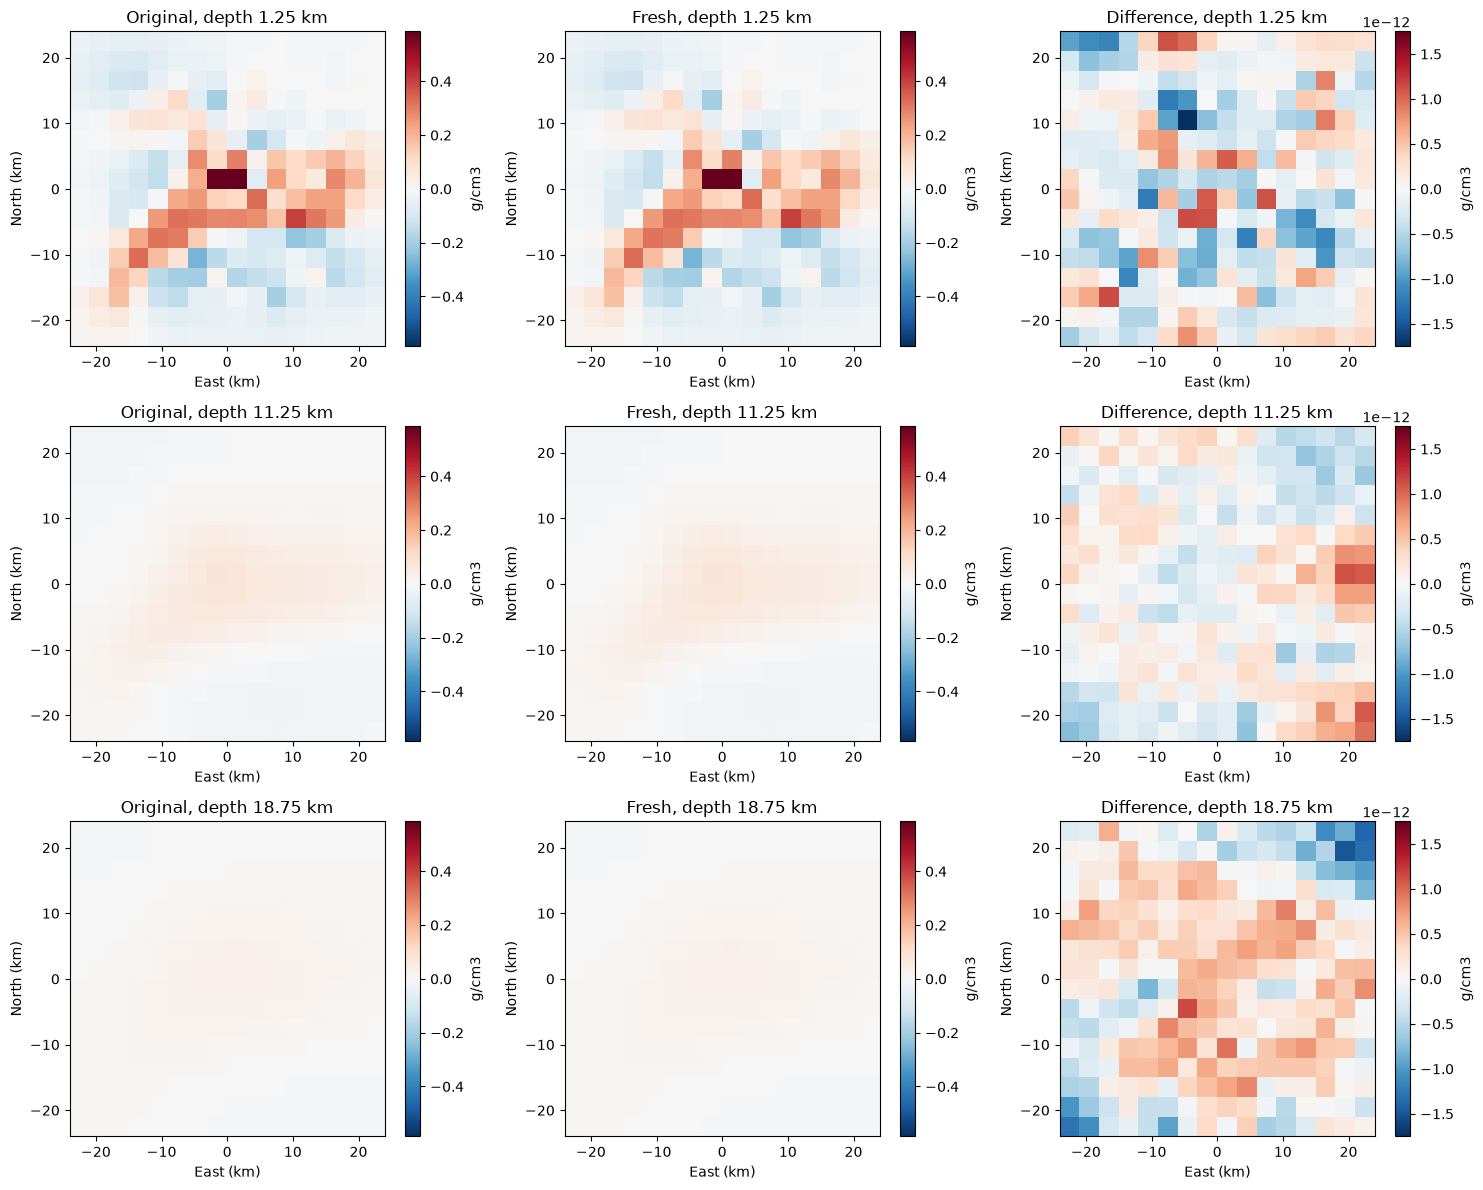

In [3]:
fig,axes=plt.subplots(3,3,figsize=(15,12))
indices=[7,3,0];limit=np.max(np.abs(np.stack([fresh,reference])));diff=fresh-reference
for row,index in enumerate(indices):
    depth=-(index*2500.-18750.)/1000
    for col,volume,title in [(0,reference,'Original'),(1,fresh,'Fresh'),(2,diff,'Difference')]:
        bound=limit if col<2 else max(np.max(np.abs(diff)),1e-15)
        image=density_slice(axes[row,col],volume,index,f'{title}, depth {depth:.2f} km',(-bound,bound));fig.colorbar(image,ax=axes[row,col],label='g/cm3')
save_group(fig,'02_density_volume',fresh=fresh,upstream=reference,difference=diff,depth_indices=np.array(indices),x_centers=np.arange(16)*3000.-22500.,y_centers=np.arange(16)*3000.-22500.,z_centers=np.arange(8)*2500.-18750.)


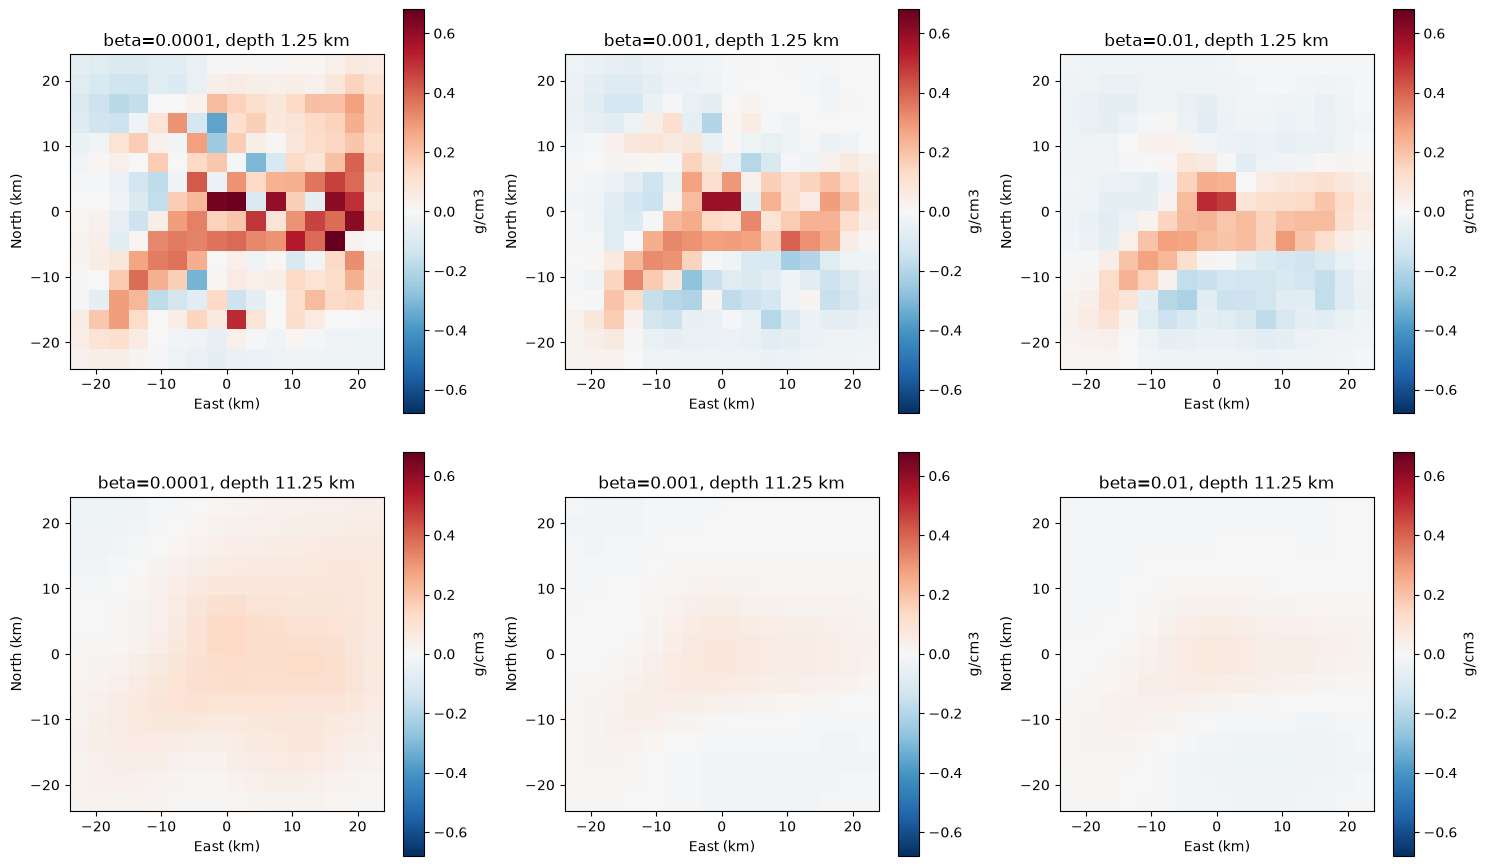

[{'beta': 0.0001,
  'rms_mgal': 1.5919461418365082,
  'regularizer_norm': 351.43191548083183,
  'seconds': 2.6887291000020923},
 {'beta': 0.001,
  'rms_mgal': 1.7411629807404885,
  'regularizer_norm': 205.61322743638524,
  'seconds': 2.2806541999998444},
 {'beta': 0.01,
  'rms_mgal': 2.1532671349691275,
  'regularizer_norm': 154.7251374949627,
  'seconds': 2.133099200000288}]

In [4]:
betas=np.array([.0001,.001,.01]);sensitivity=[];sensitivity_rms=[];sensitivity_norm=[];sensitivity_seconds=[]
for beta in betas:
    start=time.perf_counter();volume,current=reconstruct(data,beta=float(beta))
    sensitivity_seconds.append(time.perf_counter()-start);sensitivity.append(volume)
    sensitivity_rms.append(np.sqrt(np.mean((current['prediction']-current['anomaly'])**2)))
    sensitivity_norm.append(np.linalg.norm(current['regularizer']@volume.ravel()))
sensitivity=np.array(sensitivity);sensitivity_rms=np.array(sensitivity_rms);sensitivity_norm=np.array(sensitivity_norm)
fig,axes=plt.subplots(2,3,figsize=(15,9))
limit=np.max(np.abs(sensitivity))
for row,index in enumerate([7,3]):
    for col,beta in enumerate(betas):
        image=density_slice(axes[row,col],sensitivity[col],index,f'beta={beta:g}, depth {-(index*2500.-18750.)/1000:.2f} km',(-limit,limit));fig.colorbar(image,ax=axes[row,col],label='g/cm3')
save_group(fig,'03_regularization_sensitivity',betas=betas,volumes=sensitivity,residual_rms=sensitivity_rms,regularization_norm=sensitivity_norm,runtime_seconds=np.array(sensitivity_seconds),slice_indices=np.array([7,3]))
display([dict(beta=float(b),rms_mgal=float(r),regularizer_norm=float(n),seconds=float(t)) for b,r,n,t in zip(betas,sensitivity_rms,sensitivity_norm,sensitivity_seconds)])


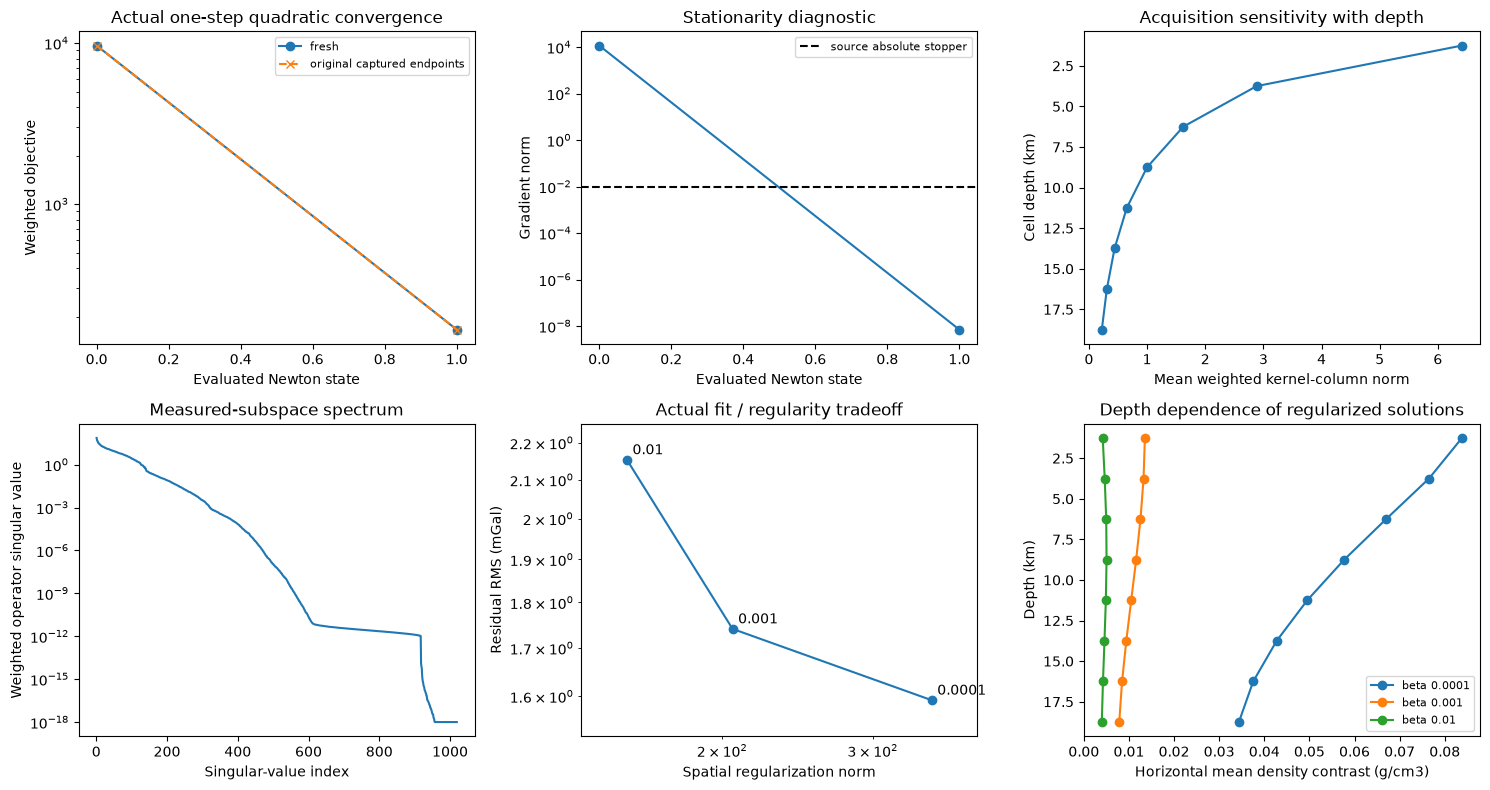

2475

In [5]:
fig,axes=plt.subplots(2,3,figsize=(15,8))
history=state['history'];iterations=np.arange(len(history))
axes[0,0].semilogy(iterations,history[:,0],'o-',label='fresh');axes[0,0].semilogy([0,1],upstream['objective'],'x--',label='original captured endpoints')
axes[0,0].set(xlabel='Evaluated Newton state',ylabel='Weighted objective',title='Actual one-step quadratic convergence');axes[0,0].legend(fontsize=8)
axes[0,1].semilogy(iterations,np.maximum(history[:,3],1e-20),'o-');axes[0,1].axhline(.01,color='k',ls='--',label='source absolute stopper')
axes[0,1].set(xlabel='Evaluated Newton state',ylabel='Gradient norm',title='Stationarity diagnostic');axes[0,1].legend(fontsize=8)
norm_by_cell=np.linalg.norm(state['projected_kernel']/5,axis=0).reshape(8,16,16);depths=-(np.arange(8)*2500.-18750.)/1000
axes[0,2].plot(np.mean(norm_by_cell,axis=(1,2)),depths,'o-');axes[0,2].invert_yaxis();axes[0,2].set(xlabel='Mean weighted kernel-column norm',ylabel='Cell depth (km)',title='Acquisition sensitivity with depth')
singular=np.linalg.svd(state['projected_kernel']/5,compute_uv=False)
axes[1,0].semilogy(np.arange(1,len(singular)+1),np.maximum(singular,1e-18));axes[1,0].set(xlabel='Singular-value index',ylabel='Weighted operator singular value',title='Measured-subspace spectrum')
axes[1,1].loglog(sensitivity_norm,sensitivity_rms,'o-')
for n,r,b in zip(sensitivity_norm,sensitivity_rms,betas):axes[1,1].annotate(f'{b:g}',(n,r),xytext=(4,4),textcoords='offset points')
axes[1,1].set(xlabel='Spatial regularization norm',ylabel='Residual RMS (mGal)',title='Actual fit / regularity tradeoff')
axes[1,1].margins(x=.15,y=.15)
for volume,beta in zip(sensitivity,betas):axes[1,2].plot(np.mean(volume,axis=(1,2)),depths,'o-',label=f'beta {beta:g}')
axes[1,2].invert_yaxis();axes[1,2].set(xlabel='Horizontal mean density contrast (g/cm3)',ylabel='Depth (km)',title='Depth dependence of regularized solutions');axes[1,2].legend(fontsize=8)
save_group(fig,'04_convergence_observability',fresh_history=history,upstream_objective=upstream['objective'],kernel_column_norm=norm_by_cell,depth_km=depths,singular_values=singular,betas=betas,sensitivity_regularization=sensitivity_norm,sensitivity_rms=sensitivity_rms,depth_mean_density=np.mean(sensitivity,axis=(2,3)))
(export/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')


## 6. Conclusion

The comparisons support reproduction of a conditional effective-density inverse. Approximate terrain reductions, regional projection, finite volume and weak depth sensitivity prevent unique volcanic-structure identification or a claim of 3 km physical resolution.

### Interpretation and limits

The fresh local inverse reproduces the independent original prism, regularizer and Newton-CG solution and passes the standalone spatial/measurement evaluator. Every displayed map and sensitivity was computed in this execution. The field is an effective density-contrast volume under adopted normal-gravity, slab, regional-plane and finite-domain assumptions, with no actual underground truth available.

The result demonstrates a spatial inverse distinct from gravity continuation: density within a three-dimensional source volume is inferred from surface observations. It does not demonstrate unique volcanic structure, complete terrain correction, known instrument noise, or 3 km spatial resolution. The private provenance report records original source revision, public-domain data rights, data hashes, environments and actual validation commands.
